# №11 зертханалық жұмыс
## Уақыт қатарларын дайындау, уақыттық белгілерді қалыптастыру және болжау модельдерін құру.

Синтетикалық күнделікті сұраныс, кеңейетін фолдтар және соңғы 21 test күні. Негізгі тәжірибеде әр болжамнан кейін жаңа нақты мән келесі күнге дейін қолжетімді болады. Бір шығару сәтінен Ridge-тің жеті рекурсивті болжамын бөлек тексереміз. CSV, екі сурет және толық хаттама `lab11_artifacts` ішінде сақталады. Деректерді алу үшін желі қажет емес.

### Орта

Бағалау алдында нұсқаларды бекітіп, кандидаттардың екі торын жариялаймыз.

In [1]:
from importlib.metadata import version
from pathlib import Path
import json
import os
import platform

import matplotlib
matplotlib.use("Agg")
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

ROOT = Path.cwd() / "lab11_artifacts"
DATASETS = ROOT / "datasets"
FIGURES = ROOT / "figures"
PACKAGES = ("numpy", "pandas", "scikit-learn", "matplotlib", "threadpoolctl")
THREAD_ENVIRONMENT = ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                      "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS")
WARM_UP = 14
TEST_DAYS = 21
FEATURE_NAMES = ["lag_1", "lag_7", "lag_14", "mean_previous_7",
                 "weekday_sin", "weekday_cos", "time_index", "planned_promo"]
RIDGE = "Ridge"
HIST = "HistGradientBoosting"
BASELINE = "Seasonal naive"
SPECS = [(BASELINE, None)] + [(RIDGE, alpha) for alpha in (.1, 1, 10, 100)] + [(HIST, leaves) for leaves in (7, 15)]
plt.rcParams["font.family"] = "DejaVu Sans"


from IPython.display import Image, display

FIGURES.mkdir(parents=True, exist_ok=True)
for package in PACKAGES:
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2
threadpoolctl 3.7.0


### 1–3-қадамдар. Деректер, шығару сәті және test шекарасы

t күні аяқталады, осы күннің нақты мәні қолжетімді, мақсат s = t + 1. Науқан күнтізбесі алдын ала белгілі. Алғашқы 203 күн dev, соңғы 21 күн test құрайды. Алғашқы 14 бақылау лагтарға тарих береді.

In [2]:
def make_series():
    dates = pd.date_range("2025-01-06", periods=224, freq="D")
    days = np.arange(len(dates))
    week = np.array([3, 4, 3, 2, 0, -5, -8])
    promo = ((days % 17 == 5) | (days % 29 == 8)).astype(int)
    innovations = np.random.default_rng(2026).normal(0, 2.3, len(dates))
    residual = innovations.copy()
    for day in range(1, len(dates)):
        residual[day] += .6 * residual[day - 1]
    demand = (85 + .06 * days + week[dates.dayofweek] + 3 * np.cos(2 * np.pi * days / 56)
              + 8 * promo + residual)
    return pd.DataFrame({"date": dates, "demand_units": np.round(demand, 3), "planned_promo": promo})


def known_features(frame):
    angle = 2 * np.pi * frame["date"].dt.dayofweek.to_numpy() / 7
    return np.column_stack([np.sin(angle), np.cos(angle), np.arange(len(frame)), frame["planned_promo"]])


def feature_row(history, known):
    return np.array([history[-1], history[-7], history[-14], np.mean(history[-7:]), *known])


def prepare_dev(frame):
    y = frame["demand_units"].to_numpy()
    known = known_features(frame)
    dev_end = len(frame) - TEST_DAYS
    dev_days = np.arange(WARM_UP, dev_end)
    test_days = np.arange(dev_end, len(frame))
    X_dev = np.array([feature_row(y[:day], known[day]) for day in dev_days])
    return {"y": y, "known": known, "dev_end": dev_end, "dev_days": dev_days,
            "test_days": test_days, "X_dev": X_dev}


frame = make_series()
data = prepare_dev(frame)
assert frame["date"].is_unique
assert frame["date"].diff().dropna().eq(pd.Timedelta(days=1)).all()
print(frame.head().to_string(index=False))
print("Бастапқы жинақталу, dev мақсатты жолдары, test", WARM_UP, len(data["dev_days"]), len(data["test_days"]))


      date  demand_units  planned_promo
2025-01-06        89.176              0
2025-01-07        91.500              0
2025-01-08        86.359              0
2025-01-09        90.410              0
2025-01-10        89.650              0
Бастапқы жинақталу, dev мақсатты жолдары, test 14 189 21


### 4-қадам. Бір күннің белгілері және болжау функциялары

Мақсатты s күні үшін 1, 7, 14 лагтарын және алдыңғы жеті мәннің орташа шамасын қолданамыз. Болжам алынғаннан кейін режимге қарай нақты мәнді қосуға немесе рекурсивті болжамды қалдыруға болады.

In [3]:
def new_model(family, value):
    if family == BASELINE:
        return None
    if family == RIDGE:
        return make_pipeline(StandardScaler(), Ridge(alpha=value))
    return HistGradientBoostingRegressor(max_leaf_nodes=value, max_iter=120,
                                         learning_rate=.05, min_samples_leaf=8,
                                         l2_regularization=.2, early_stopping=False,
                                         random_state=2026)


def predict_day(model, history, known):
    if model is None:
        return float(history[-7])
    return float(model.predict(feature_row(history, known)[None, :])[0])


def observed_updates(model, y, known, days):
    history = y[:days[0]].tolist()
    forecasts = []
    for day in days:
        forecasts.append(predict_day(model, history, known[day]))
        history.append(float(y[day]))
    return np.array(forecasts)


def fixed_origin(model, initial_history, known, days):
    history = list(initial_history)
    forecasts = []
    for day in days:
        prediction = predict_day(model, history, known[day])
        forecasts.append(prediction)
        history.append(prediction)
    return np.array(forecasts)


first = int(data["dev_days"][0])
print("Алғашқы мақсатты күн", frame["date"].iloc[first].date())
print(pd.Series(data["X_dev"][0], index=FEATURE_NAMES).to_string())


Алғашқы мақсатты күн 2025-01-20
lag_1              78.518000
lag_7              90.937000
lag_14             89.176000
mean_previous_7    88.410143
weekday_sin         0.000000
weekday_cos         1.000000
time_index         14.000000
planned_promo       0.000000


### 5–6-қадамдар. Кеңейетін тексеру

Әрқайсысында 14 validation күні бар төрт фолд. Әр фолдта оның train бөлігінде жаңа конвейер үйретіп, тексеру ішінде тарихты нақты мәнмен бірізді жаңартамыз. Әр модель тобының параметрін орташа MAE бойынша таңдаймыз. Тең болса, алдын ала жарияланған реттегі біріншісін аламыз.

Seasonal naive None фолд MAE [3.025214 5.300357 3.899643 4.297   ] орташа 4.130554
Ridge 0.1 фолд MAE [2.185311 3.475781 3.679423 1.916347] орташа 2.814215
Ridge 1 фолд MAE [2.187088 3.488418 3.67079  1.921337] орташа 2.816908
Ridge 10 фолд MAE [2.199267 3.61872  3.58781  1.963106] орташа 2.842226
Ridge 100 фолд MAE [2.238177 4.723356 3.25899  2.311759] орташа 3.133070
HistGradientBoosting 7 фолд MAE [1.668641 6.003675 2.828329 3.36936 ] орташа 3.467501
HistGradientBoosting 15 фолд MAE [1.378396 6.902487 2.686293 3.466481] орташа 3.608414
Таңдалған конфигурациялар {'Ridge': 0.1, 'HistGradientBoosting': 7}


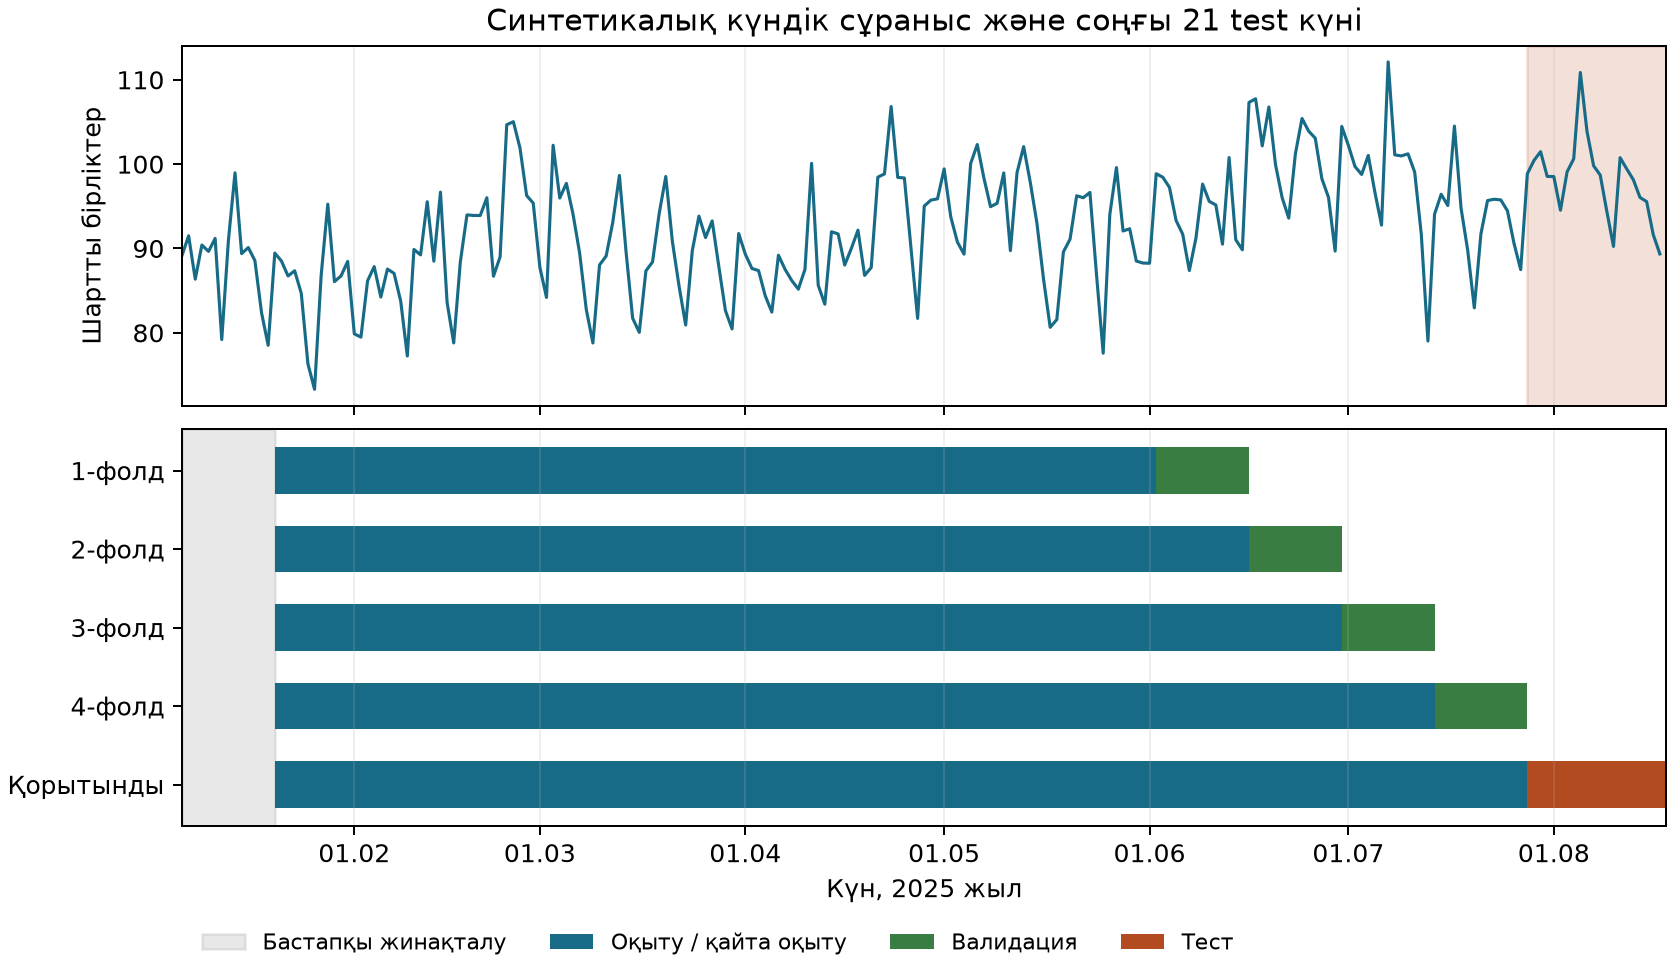

In [4]:
def expanding_validation(frame, data):
    X, y, known, days = (data[key] for key in ("X_dev", "y", "known", "dev_days"))
    dev_end = data["dev_end"]
    folds = list(TimeSeriesSplit(n_splits=4, test_size=14, gap=0).split(X))
    fold_records = []
    dates = frame["date"].dt.strftime("%Y-%m-%d").tolist()
    for train, validation in folds:
        t, v = days[train], days[validation]
        fold_records.append({"train_days": t.tolist(), "validation_days": v.tolist(),
                             "train_last_date": dates[t[-1]], "validation_first_date": dates[v[0]],
                             "validation_last_date": dates[v[-1]]})
    rows = []
    with threadpool_limits(limits=1):
        for family, value in SPECS:
            errors, predictions = [], []
            for train, validation in folds:
                model = new_model(family, value)
                if model is not None:
                    model.fit(X[train], y[days[train]])
                pred = observed_updates(model, y[:dev_end], known[:dev_end], days[validation])
                errors.append(float(mean_absolute_error(y[days[validation]], pred)))
                predictions.append(pred.tolist())
            rows.append({"family": family, "value": value, "fold_MAE": errors,
                         "mean_MAE": float(np.mean(errors)), "fold_predictions": predictions})
    chosen = {family: min((row for row in rows if row["family"] == family),
                          key=lambda row: row["mean_MAE"])["value"] for family in (RIDGE, HIST)}
    for row in rows:
        print(row["family"], row["value"], "фолд MAE", np.round(row["fold_MAE"], 6),
              f"орташа {row['mean_MAE']:.6f}")
    print("Таңдалған конфигурациялар", chosen)
    return {"rows": rows, "folds": fold_records, "selected": chosen, "selection_metric": "фолдтардың орташа MAE мәні",
            "tie_rule": "бекітілген реттегі бірінші кандидат", "learned_fit_count": (len(SPECS) - 1) * len(folds)}


def plot_splits(frame, data, validation, path):
    fig, axes = plt.subplots(2, 1, figsize=(9.3, 5.4), sharex=True, layout="constrained",
                             gridspec_kw={"height_ratios": [1, 1.1]})
    dates = mdates.date2num(frame["date"])
    first_test = dates[data["dev_end"]]
    axes[0].plot(dates, frame["demand_units"], color="#176B87", linewidth=1.25)
    axes[0].axvspan(first_test, dates[-1] + 1, color="#B34B20", alpha=.17)
    axes[0].set(title="Синтетикалық күндік сұраныс және соңғы 21 test күні",
                ylabel="Шартты бірліктер")
    axis = axes[1]
    axis.axvspan(dates[0], dates[WARM_UP], color="#777777", alpha=.17, label="Бастапқы жинақталу")
    for position, fold in enumerate(validation["folds"]):
        train, val = fold["train_days"], fold["validation_days"]
        axis.barh(position, len(train), left=dates[train[0]], height=.59, color="#176B87",
                  label="Оқыту / қайта оқыту" if position == 0 else None)
        axis.barh(position, len(val), left=dates[val[0]], height=.59, color="#3A7D43",
                  label="Валидация" if position == 0 else None)
    axis.barh(4, len(data["dev_days"]), left=dates[WARM_UP], height=.59, color="#176B87")
    axis.barh(4, len(data["test_days"]), left=first_test, height=.59, color="#B34B20", label="Тест")
    axis.set(yticks=np.arange(5), yticklabels=["1-фолд", "2-фолд", "3-фолд", "4-фолд", "Қорытынды"],
             xlim=(dates[0], dates[-1] + 1), xlabel="Күн, 2025 жыл")
    axis.invert_yaxis()
    axis.xaxis.set_major_locator(mdates.MonthLocator())
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    axis.legend(ncols=4, loc="upper left", bbox_to_anchor=(0, -.22), fontsize=8.7, frameon=False)
    for ax in axes:
        ax.grid(axis="x", alpha=.2)
    fig.savefig(path, dpi=180)
    plt.close(fig)


validation = expanding_validation(frame, data)
plot_splits(frame, data, validation, FIGURES / "ch11_05_temporal_splits.png")
display(Image(filename=str(FIGURES / "ch11_05_temporal_splits.png")))


### 7–8-қадамдар. Қорытынды one-step

Таңдаудан кейін Ridge пен гистограммалық бустингті dev ішіндегі 189 мақсатты жолда қайта үйретеміз. 21 күннің әрқайсысында қолжетімді тарихтан болжам есептеп, содан кейін жаңа нақты мәнді қосамыз. Test кезінде модельдер қайта үйретілмейді.

In [5]:
def final_one_step(frame, data, validation):
    X, y, known = (data[key] for key in ("X_dev", "y", "known"))
    dev_days, test_days = data["dev_days"], data["test_days"]
    models = {BASELINE: None}
    rows, predictions = [], {}
    with threadpool_limits(limits=1):
        for family, value in validation["selected"].items():
            models[family] = new_model(family, value).fit(X, y[dev_days])
        for family, model in models.items():
            forecast = observed_updates(model, y, known, test_days)
            predictions[family] = forecast.tolist()
            rows.append({"family": family, "MAE": float(mean_absolute_error(y[test_days], forecast)),
                         "RMSE": float(root_mean_squared_error(y[test_days], forecast))})
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda value: f"{value:.6f}"))
    return models, {"rows": rows, "predictions": predictions, "observed": y[test_days].tolist(),
                    "dates": frame["date"].iloc[test_days].dt.strftime("%Y-%m-%d").tolist(),
                    "dev_fit_rows": len(dev_days), "test_indices": test_days.tolist(), "test_refits": 0,
                    "update": "s мақсатты күнін болжау, содан кейін бақыланған y[s] мәнін қосу"}


models, test = final_one_step(frame, data, validation)
print("Алғашқы және соңғы test күндері", test["dates"][0], test["dates"][-1])


              family      MAE     RMSE
      Seasonal naive 4.419524 5.660787
               Ridge 2.370039 2.984795
HistGradientBoosting 1.926470 2.518757
Алғашқы және соңғы test күндері 2025-07-28 2025-08-17


### 9-қадам. Бір origin сәтінен жеті күн

Рекурсивті функция нақты мәндерді тек 27 шілдеге дейін, оны қоса алады. Бірінші болжамнан кейін келесі күннің 1 лагын құру үшін өз нәтижесін қосады. Сол Ridge моделінің сол жеті күндегі MAE мәндерін салыстырамыз.

Алғашқы жеті күн, Ridge MAE: нақты мәндермен жаңарту 2.876570; бекітілген басталу 4.722244


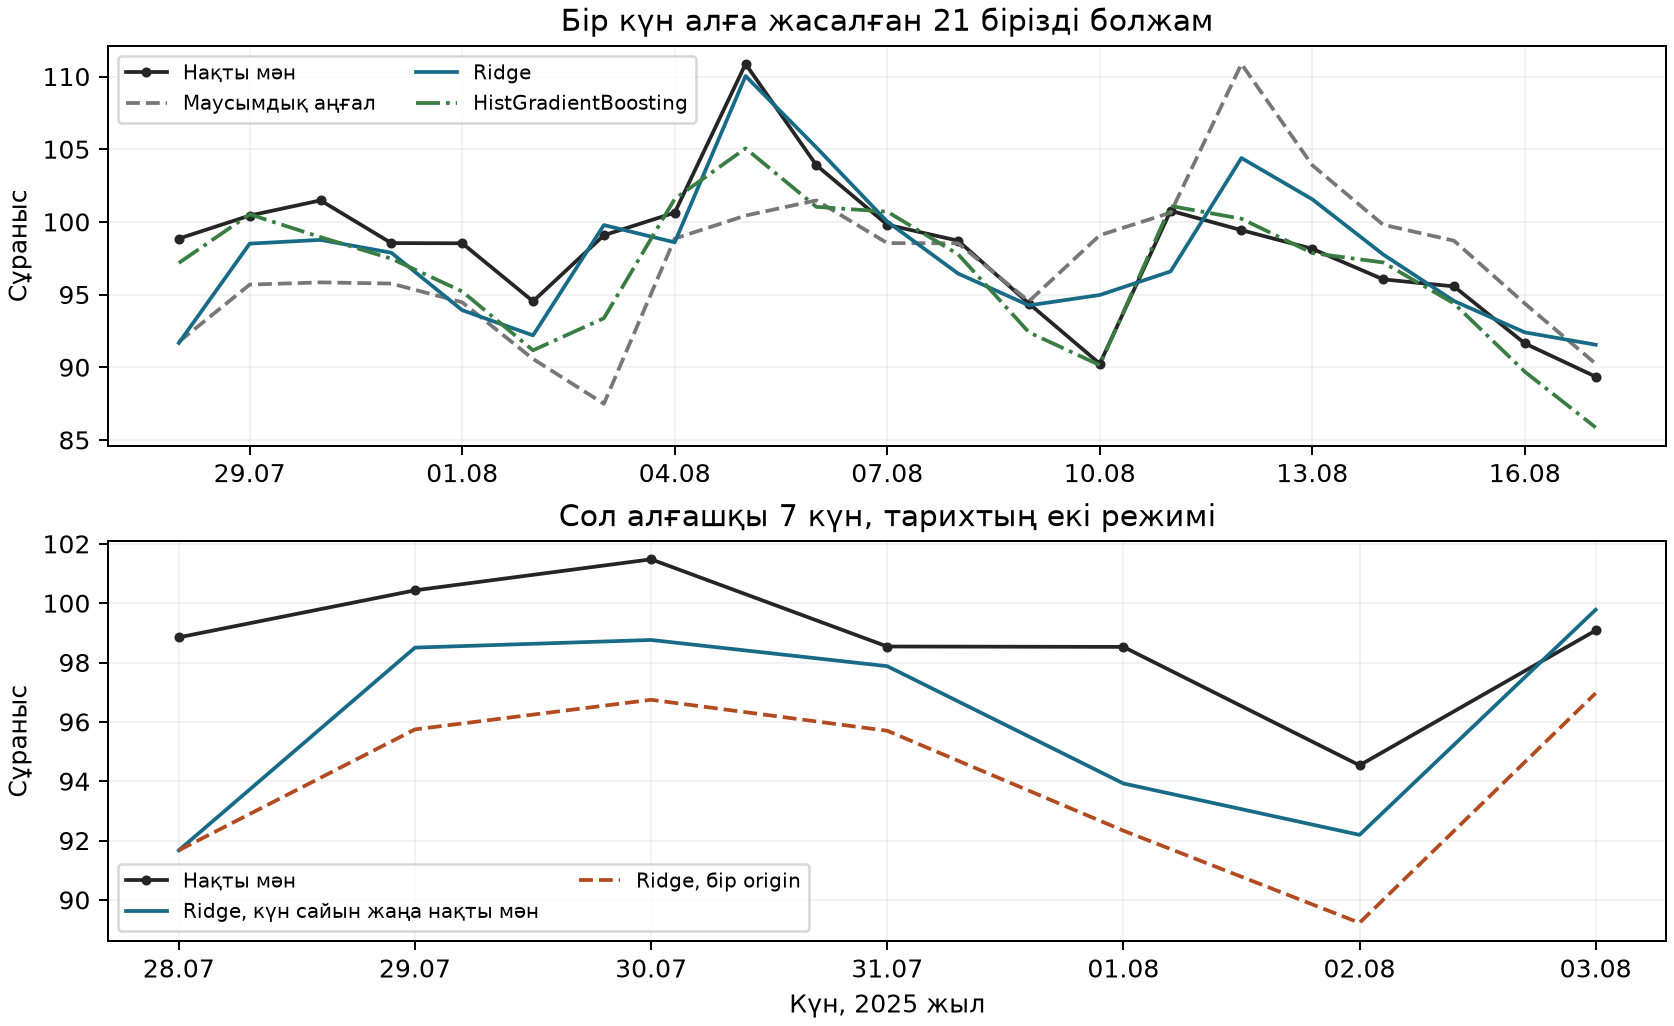

In [6]:
def fixed_origin_comparison(frame, data, model, test):
    days = data["test_days"][:7]
    y, known = data["y"], data["known"]
    with threadpool_limits(limits=1):
        recursive = fixed_origin(model, y[:days[0]], known, days)
        baseline_recursive = fixed_origin(None, y[:days[0]], known, days)
    rolling = np.array(test["predictions"][RIDGE][:len(days)])
    np.testing.assert_allclose(recursive[0], rolling[0], rtol=0, atol=1e-12)
    np.testing.assert_array_equal(baseline_recursive, test["predictions"][BASELINE][:len(days)])
    observed = y[days]
    result = {"forecast_origin_date": frame["date"].iloc[days[0] - 1].strftime("%Y-%m-%d"),
              "dates": test["dates"][:len(days)], "horizons": list(range(1, len(days) + 1)),
              "observed": observed.tolist(), "observed_update_forecasts": rolling.tolist(),
              "fixed_origin_forecasts": recursive.tolist(), "seasonal_naive_same_for_h1_to_h7": True,
              "observed_update_MAE": float(mean_absolute_error(observed, rolling)),
              "fixed_origin_MAE": float(mean_absolute_error(observed, recursive)),
              "recursive_update": "болжамды қосу, болашақ нақты мақсат кіріске берілмейді", "refits": 0}
    print(f"Алғашқы жеті күн, Ridge MAE: нақты мәндермен жаңарту {result['observed_update_MAE']:.6f}; "
          f"бекітілген басталу {result['fixed_origin_MAE']:.6f}")
    return result


def plot_forecasts(test, comparison, path):
    fig, axes = plt.subplots(2, 1, figsize=(9.3, 5.7), layout="constrained")
    days = pd.to_datetime(test["dates"])
    axes[0].plot(days, test["observed"], color="#252525", label="Нақты мән", marker="o", markersize=3)
    for name, label, color, linestyle in ((BASELINE, "Маусымдық аңғал", "#777777", "--"),
                                          (RIDGE, RIDGE, "#176B87", "-"),
                                          (HIST, HIST, "#3A7D43", "-.")):
        axes[0].plot(days, test["predictions"][name], color=color, linestyle=linestyle, label=label)
    axes[0].set(title="Бір күн алға жасалған 21 бірізді болжам", ylabel="Сұраныс")
    short = pd.to_datetime(comparison["dates"])
    axes[1].plot(short, comparison["observed"], color="#252525", label="Нақты мән", marker="o", markersize=3)
    axes[1].plot(short, comparison["observed_update_forecasts"], color="#176B87", label="Ridge, күн сайын жаңа нақты мән")
    axes[1].plot(short, comparison["fixed_origin_forecasts"], color="#B34B20", linestyle="--",
                 label="Ridge, бір origin")
    axes[1].set(title="Сол алғашқы 7 күн, тарихтың екі режимі", ylabel="Сұраныс", xlabel="Күн, 2025 жыл")
    for axis, interval in zip(axes, (3, 1)):
        axis.xaxis.set_major_locator(mdates.DayLocator(interval=interval))
        axis.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
        axis.legend(ncols=2, fontsize=8.1, loc="best")
        axis.grid(alpha=.16)
    fig.savefig(path, dpi=180)
    plt.close(fig)


comparison = fixed_origin_comparison(frame, data, models[RIDGE], test)
plot_forecasts(test, comparison, FIGURES / "ch11_06_forecast_modes.png")
display(Image(filename=str(FIGURES / "ch11_06_forecast_modes.png")))


**Жауабыңыз.** Екінші мақсатты күнде 1 лагы қай мәннен құрылатынын көрсетіңіз. Алғашқы болжамның сәйкестігі кейінгі болжамдардың ажырауымен неліктен үйлесетінін түсіндіріңіз.

_Өз қорытындыңызды жазыңыз._

### Қолжетімсіз нақты мәндерді бақылау

Қатар көшірмесінде 1 тамыздан бастап 500 бірлік қосамыз. Осы мақсатты күнге дейін, оны қоса болжамдарды салыстырамыз. Өзгерген нақты мәнді қолдануға рұқсат етілген келесі күнді де тексереміз.

In [7]:
def availability_probe(frame, data, model):
    days = data["test_days"][:6]
    cutoff = days[4]
    y, known = data["y"], data["known"]
    changed = y.copy()
    changed[cutoff:] += 500
    with threadpool_limits(limits=1):
        original = observed_updates(model, y, known, days)
        perturbed = observed_updates(model, changed, known, days)
    np.testing.assert_array_equal(original[:5], perturbed[:5])
    assert not np.isclose(original[5], perturbed[5])
    date = frame["date"].iloc[cutoff].strftime("%Y-%m-%d")
    result = {"family": RIDGE, "first_changed_actual_date": date, "added_demand_units": 500,
              "unchanged_forecast_count": 5, "forecasts_through_cutoff_equal": True,
              "following_day_forecast_original": float(original[5]),
              "following_day_forecast_perturbed": float(perturbed[5]),
              "model_refitted": False}
    print("Қолжетімсіз мақсатты тексеру:", date, "алғашқы бес болжам дәл бірдей")
    return result


probe = availability_probe(frame, data, models[RIDGE])
print("2 тамыз болжамы, бастапқы және алмастырғаннан кейінгі",
      probe["following_day_forecast_original"], probe["following_day_forecast_perturbed"])


Қолжетімсіз мақсатты тексеру: 2025-08-01 алғашқы бес болжам дәл бірдей
2 тамыз болжамы, бастапқы және алмастырғаннан кейінгі 92.19112657202264 284.22786221202915


### 10-қадам. Экспорт және өзін-өзі тексеру

CSV және JSON сақтаймыз. Бөліктер ұзындығын, оқыту кезеңдерінің кеңеюін, хронологияны және test кезінде модельдердің өзгермейтінін тексереміз.

In [8]:
def save_results(frame, data, models, validation, test, comparison, probe, output):
    DATASETS.mkdir(parents=True, exist_ok=True)
    csv_path = DATASETS / "synthetic_daily_demand.csv"
    frame.to_csv(csv_path, index=False, date_format="%Y-%m-%d", float_format="%.3f")
    reconstructed = pd.read_csv(csv_path, parse_dates=["date"], float_precision="round_trip")
    pd.testing.assert_frame_equal(reconstructed, frame, check_exact=True)
    parameters = {family: model.get_params(deep=False) if family == HIST else {
        "StandardScaler": model.named_steps["standardscaler"].get_params(),
        "Ridge": model.named_steps["ridge"].get_params()}
        for family, model in models.items() if model is not None}
    result = {"synthetic": True, "generator_seed": 2026, "n_observations": len(frame), "frequency": "D",
              "data_start": frame["date"].iloc[0].strftime("%Y-%m-%d"),
              "data_end": frame["date"].iloc[-1].strftime("%Y-%m-%d"),
              "warm_up_days": WARM_UP, "dev_days_including_warm_up": data["dev_end"],
              "supervised_dev_indices": data["dev_days"].tolist(), "feature_names": FEATURE_NAMES,
              "models": parameters, "validation": validation, "test": test, "fixed_origin": comparison,
              "availability_probe": probe,
              "runtime": {"Python": platform.python_version(), "device": "CPU",
                          "packages": {name: version(name) for name in PACKAGES},
                          "threadpoolctl_limit": 1,
                          "thread_environment": {name: os.getenv(name) for name in THREAD_ENVIRONMENT}}}
    output.write_text(json.dumps(result, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    return result


result = save_results(frame, data, models, validation, test, comparison, probe,
                      ROOT / "lab11_results.json")
folds = validation["folds"]
assert [len(fold["train_days"]) for fold in folds] == [133, 147, 161, 175]
assert [len(fold["validation_days"]) for fold in folds] == [14] * 4
assert all(fold["train_days"][-1] + 1 == fold["validation_days"][0] for fold in folds)
assert all(fold["validation_days"][-1] < test["test_indices"][0] for fold in folds)
assert test["dev_fit_rows"] == 189 and len(test["test_indices"]) == 21
assert test["test_refits"] == 0 and comparison["refits"] == 0
assert probe["forecasts_through_cutoff_equal"]
print("Күндер мен болжау режимдері тексерілді. Нәтижелер сақталған орын:", ROOT)


Күндер мен болжау режимдері тексерілді. Нәтижелер сақталған орын: lab11_artifacts


### Жеке нұсқа және қорғау

Қосымша тәжірибелер dev ішінде орындалады.

1. 28 лагын қосып, ортақ тексеру күндерін сақтаңыз.
2. Науқан жоспары бар және жоқ Ridge модельдерін салыстырыңыз.
3. Кеңейетін train мен соңғы 84 күндік терезені салыстырыңыз.
4. 1 және 7 лагтары бойынша аңғал базалық бағдарларды салыстырыңыз.
5. Алдын ала таңдалған үш origin сәтінен 1–7 көкжиектерінің қателерін салыстырыңыз.
6. Нақты мәннің бір күндік кешігуін модельдеп, белгілер терезесін өзгертіңіз.

Жергілікті рубрика 100% құрайды. Деректер мен қолжетімділік 15%, белгілер 15%, кеңейетін тексеру 20%, қорытынды one-step 20%, fixed origin және қолжетімділік тесті 15%, нұсқа, қорытынды және қайта шығарылымдылық 15% береді. Силлабус бөлек 7 ресми балл көрсетеді.

1. t мен s қалай байланысады?
2. Жеті нақты мәннің орташа шамасына қандай күндер кіреді?
3. Алғашқы 14 күн не үшін керек?
4. Күндердің тұрақтылығын қалай тексереді?
5. Стандарттау параметрлері қайда бағаланады?
6. Фолдтар қалай салыстырылады?
7. One-step тарихы қалай жаңартылады?
8. Бекітілген origin кезінде не қосылады?
9. Алғашқы болжам неліктен сәйкеседі?
10. Қолжетімсіз мәндерді алмастыру тексеруі қалай жұмыс істейді?